In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.cm import rainbow

%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [3]:
dataset = pd.read_csv('heart_cleveland_upload.csv')

dataset.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,33,0,3,132,183,0,0,137,0,0.9,1,3,1,0
1,66,1,3,128,322,0,0,114,0,1.2,1,0,0,1
2,61,1,0,110,221,0,0,160,0,2.0,0,2,0,1
3,50,0,3,104,161,0,0,140,0,2.6,1,1,0,1
4,50,1,0,144,193,0,2,125,0,1.0,1,1,0,0


In [4]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    int64  
 1   sex       297 non-null    int64  
 2   cp        297 non-null    int64  
 3   trestbps  297 non-null    int64  
 4   chol      297 non-null    int64  
 5   fbs       297 non-null    int64  
 6   restecg   297 non-null    int64  
 7   thalach   297 non-null    int64  
 8   exang     297 non-null    int64  
 9   oldpeak   297 non-null    float64
 10  slope     297 non-null    int64  
 11  ca        297 non-null    int64  
 12  thal      297 non-null    int64  
 13  target    297 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 32.6 KB


In [5]:
dataset.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000
mean,53.101010,0.643098,2.138047,132.181818,245.316498,0.164983,1.020202,148.249158,0.323232,1.255556,0.956229,0.643098,0.898990,0.727273
std,13.337228,0.479894,0.971451,17.402060,52.269386,0.371792,0.993014,22.040776,0.468500,0.989392,0.621765,0.919328,0.946133,0.446113
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,42.000000,0.000000,2.000000,121.000000,211.000000,0.000000,0.000000,133.000000,0.000000,0.400000,1.000000,0.000000,0.000000,0.000000
50%,53.000000,1.000000,2.000000,133.000000,247.000000,0.000000,2.000000,150.000000,0.000000,1.200000,1.000000,0.000000,0.000000,1.000000
75%,65.000000,1.000000,3.000000,143.000000,280.000000,0.000000,2.000000,163.000000,1.000000,2.000000,1.000000,1.000000,2.000000,1.000000
max,77.000000,1.000000,3.000000,189.000000,393.000000,1.000000,2.000000,202.000000,1.000000,4.100000,2.000000,3.000000,2.000000,1.000000


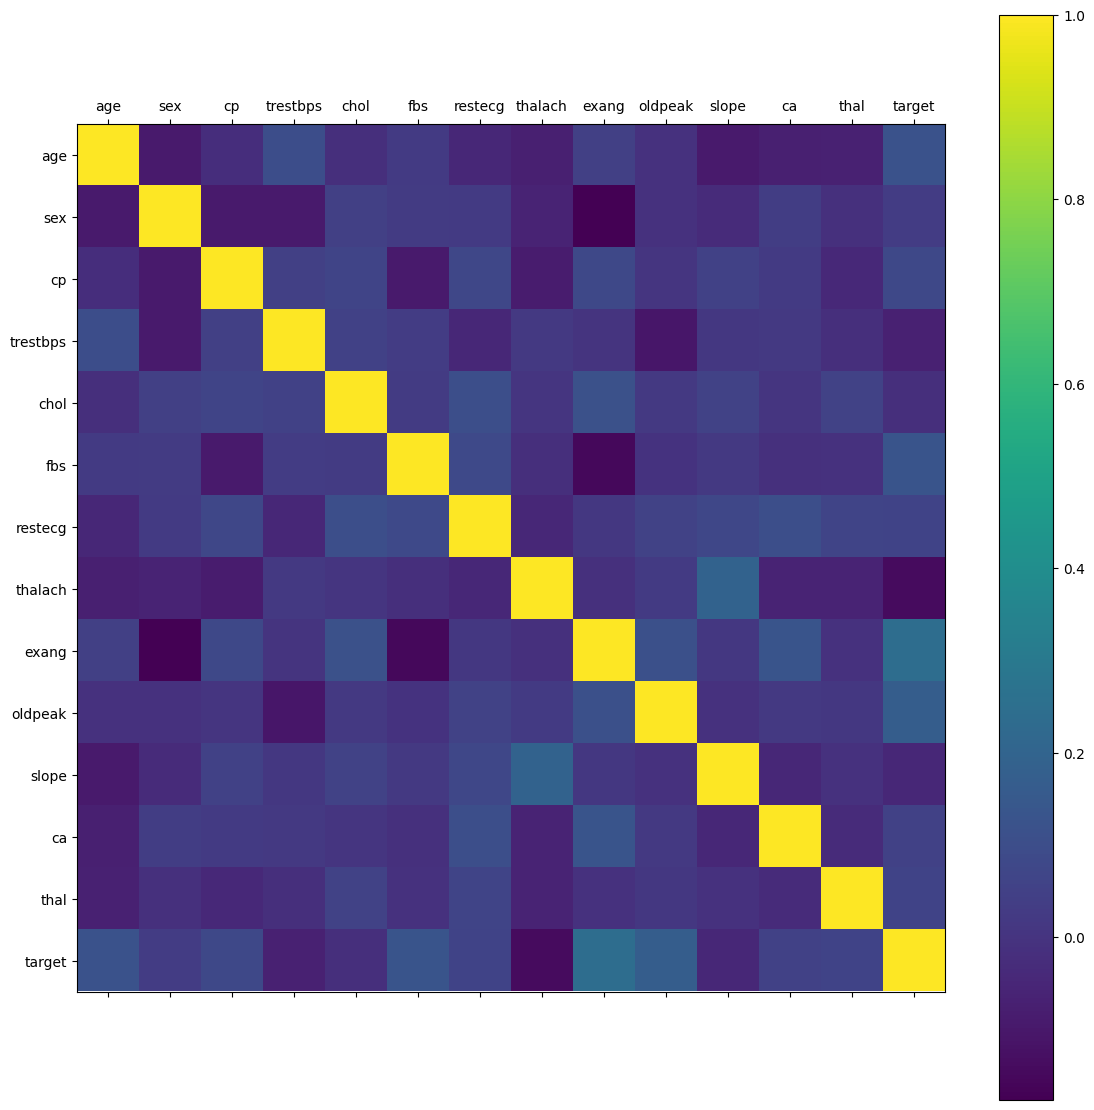

In [7]:
rcParams['figure.figsize'] = 20, 14

plt.matshow(dataset.corr())

plt.yticks(np.arange(dataset.shape[1]), dataset.columns)
plt.xticks(np.arange(dataset.shape[1]), dataset.columns)

plt.colorbar()

array([[<Axes: title={'center': 'age'}>, <Axes: title={'center': 'sex'}>,
        <Axes: title={'center': 'cp'}>,
        <Axes: title={'center': 'trestbps'}>],
       [<Axes: title={'center': 'chol'}>,
        <Axes: title={'center': 'fbs'}>,
        <Axes: title={'center': 'restecg'}>,
        <Axes: title={'center': 'thalach'}>],
       [<Axes: title={'center': 'exang'}>,
        <Axes: title={'center': 'oldpeak'}>,
        <Axes: title={'center': 'slope'}>,
        <Axes: title={'center': 'ca'}>],
       [<Axes: title={'center': 'thal'}>,
        <Axes: title={'center': 'target'}>, <Axes: >, <Axes: >]],
      dtype=object)

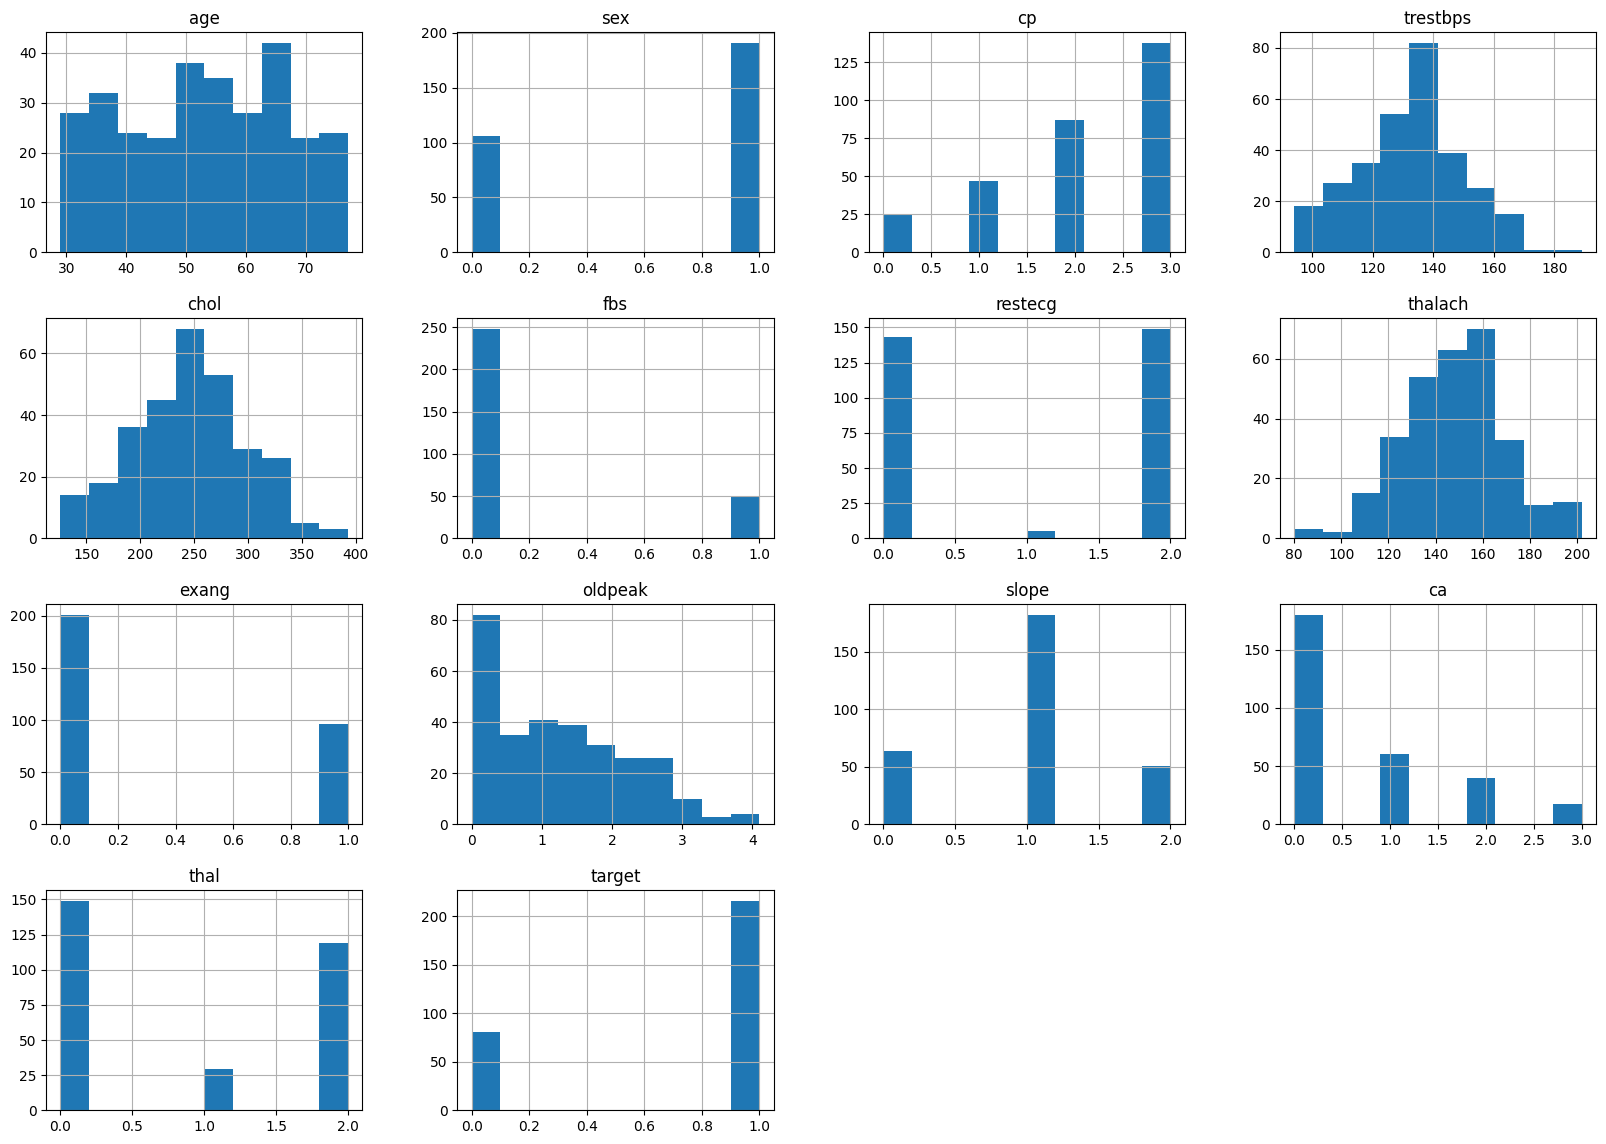

In [8]:
dataset.hist()

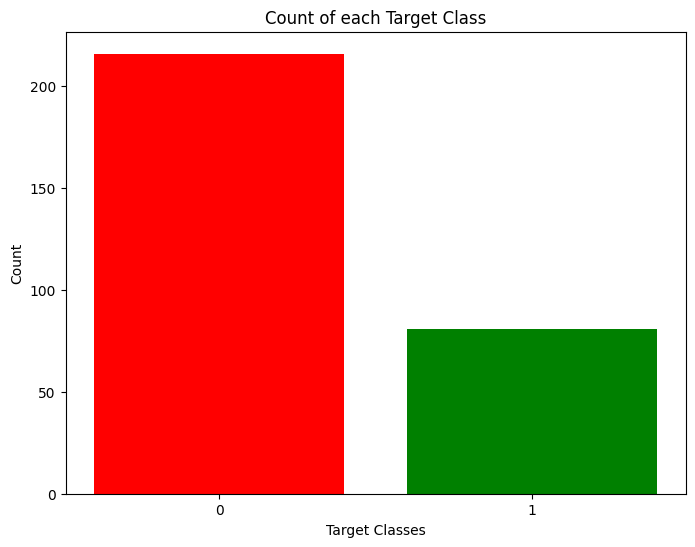

In [9]:
rcParams['figure.figsize'] = 8, 6

plt.bar(
    dataset['target'].unique(),
    dataset['target'].value_counts(),
    color=['red', 'green']
)

plt.xticks([0, 1])
plt.xlabel('Target Classes')
plt.ylabel('Count')
plt.title('Count of each Target Class')
plt.show()

In [10]:
dataset = pd.get_dummies(
    dataset,
    columns=['sex', 'cp', 'fbs', 'restecg',
             'exang', 'slope', 'ca', 'thal']
)

In [11]:
standardScaler = StandardScaler()

columns_to_scale = [
    'age', 'trestbps', 'chol', 'thalach', 'oldpeak'
]

dataset[columns_to_scale] = standardScaler.fit_transform(
    dataset[columns_to_scale]
)

In [12]:
y = dataset['target']

X = dataset.drop(['target'], axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=0
)

In [13]:
knn_scores = []

for k in range(1, 21):
    knn_classifier = KNeighborsClassifier(n_neighbors=k)

    knn_classifier.fit(X_train, y_train)

    knn_scores.append(knn_classifier.score(X_test, y_test))

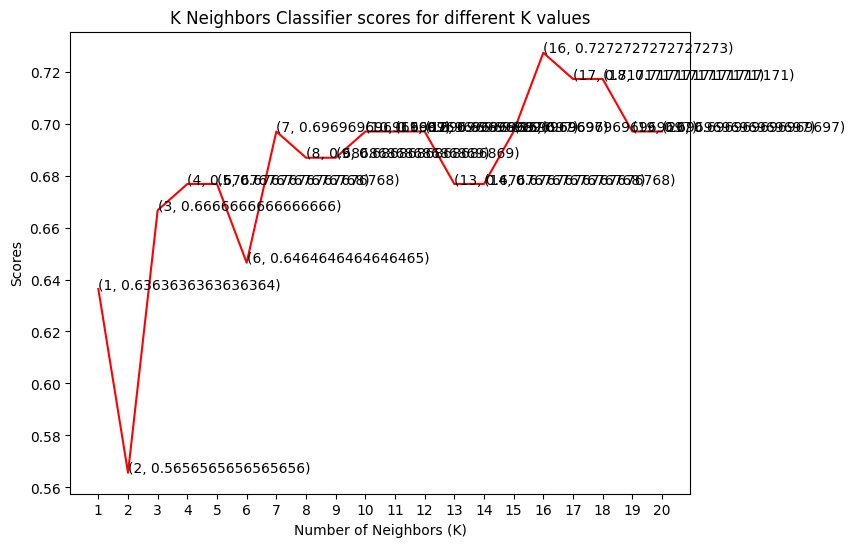

In [14]:
plt.plot(
    [k for k in range(1, 21)],
    knn_scores,
    color='red'
)

for i in range(1, 21):
    plt.text(i, knn_scores[i-1], (i, knn_scores[i-1]))

plt.xticks([i for i in range(1, 21)])
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Scores')
plt.title('K Neighbors Classifier scores for different K values')
plt.show()

In [15]:
print("The score for K Neighbors Classifier is {}% with {} neighbors.".format(
    knn_scores[7]*100, 8
))

The score for K Neighbors Classifier is 68.68686868686868% with 8 neighbors.


In [16]:
svc_scores = []

kernels = ['linear', 'poly', 'rbf', 'sigmoid']

for i in range(len(kernels)):
    svc_classifier = SVC(kernel=kernels[i])

    svc_classifier.fit(X_train, y_train)

    svc_scores.append(svc_classifier.score(X_test, y_test))

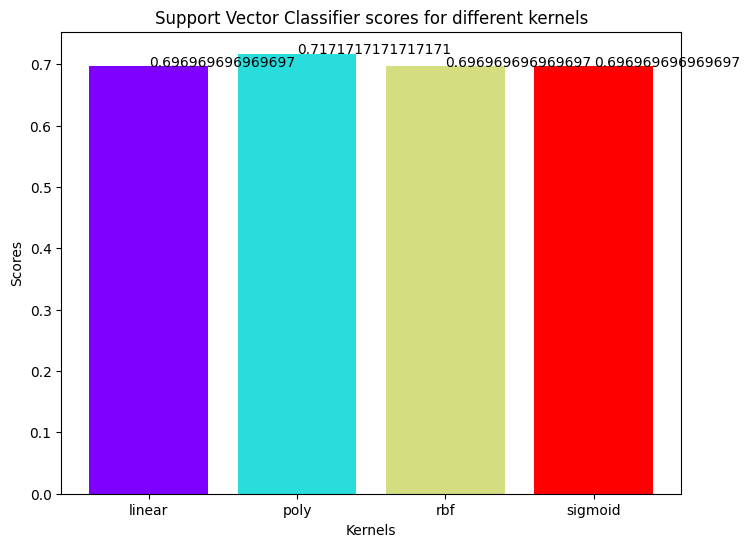

In [17]:
colors = rainbow(np.linspace(0, 1, len(kernels)))

plt.bar(kernels, svc_scores, color=colors)

for i in range(len(kernels)):
    plt.text(i, svc_scores[i], svc_scores[i])

plt.xlabel('Kernels')
plt.ylabel('Scores')
plt.title('Support Vector Classifier scores for different kernels')
plt.show()

In [18]:
print("The score for Support Vector Classifier is {}% with {} kernel.".format(
    svc_scores[0]*100, 'linear'
))

The score for Support Vector Classifier is 69.6969696969697% with linear kernel.


In [19]:
dt_scores = []

for i in range(1, len(X.columns) + 1):
    dt_classifier = DecisionTreeClassifier(
        max_features=i,
        random_state=0
    )

    dt_classifier.fit(X_train, y_train)

    dt_scores.append(dt_classifier.score(X_test, y_test))

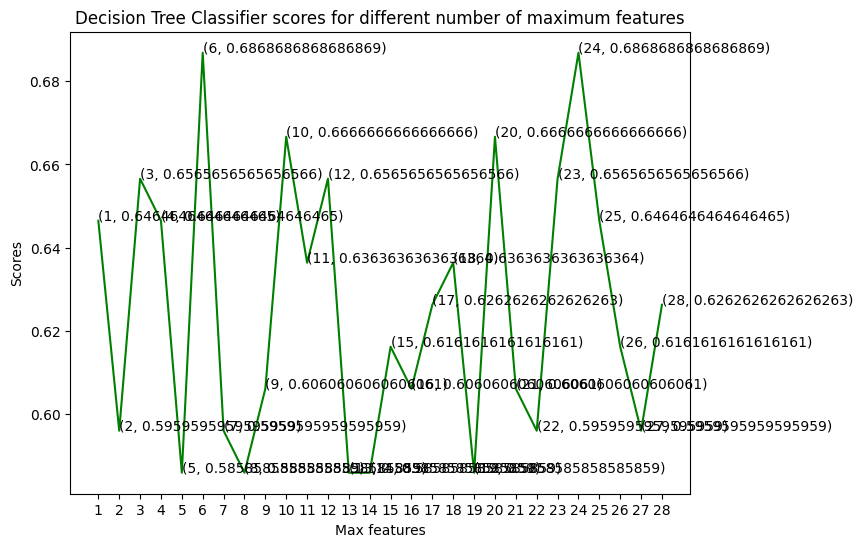

In [20]:
plt.plot(
    [i for i in range(1, len(X.columns) + 1)],
    dt_scores,
    color='green'
)

for i in range(1, len(X.columns) + 1):
    plt.text(i, dt_scores[i-1], (i, dt_scores[i-1]))

plt.xticks([i for i in range(1, len(X.columns) + 1)])
plt.xlabel('Max features')
plt.ylabel('Scores')
plt.title('Decision Tree Classifier scores for different number of maximum features')
plt.show()

In [21]:
print("The score for Decision Tree Classifier is {}% with {} maximum features.".format(
    dt_scores[17]*100, 18
))

The score for Decision Tree Classifier is 63.63636363636363% with 18 maximum features.
